# CERT analysis

The held-out score is the expected cost of the escalate-or-close rule, in units of \(C_{FP}\) and \(C_{MISS}\). It is compared with closing every USB connect. This notebook is the CERT r6.1 stand-in for `analysis.ipynb`. The main notebook, `analysis.ipynb`, is unchanged.

The five user ids below are the red-team answer key. The model scores a connect. It does not rank employees.


## Setup

The interpreter is Python 3.15.2, the version in `.python-version`. Packages are pinned in `requirements.txt`. The logistic fit is deterministic. The window simulation uses seed `20261116`. The notebook checks `device.csv`, `logon.csv`, `file.csv`, and `answers.tar.bz2` against the SHA-256 values in `cert_endpoint.py`, which match `data/README_cert.md`. `http.csv` and `email.csv` are not read.


In [1]:
%matplotlib inline
from IPython.display import Image, display
import numpy as np
import pandas as pd
from sklearn.metrics import log_loss

import cert_endpoint as cert

prepared = cert.prepare()
print("SHA-256 checks passed")
for name, digest in prepared["hashes"].items():
    print(name, digest)


SHA-256 checks passed
device.csv 4d95a992730325e0704869f2e03014132ee9f98e681d8bd9c47dbbbabb36d0ac
logon.csv 22b2671d1d8229c287837a958a3d2e26529ce3e2e6bbb8be06226d1e16064700
file.csv 25050ecf9f40d9cf599dd594b43a79790e4bce29095f5bd3cfb189a0f74bd2c7
answers.tar.bz2 ed21bf921def01e97326b314f2d1fa77651a945bd31bf513095f8ac7658c9ddd


## Question

Which USB connects should a SOC close, and which should it escalate? The quantity is the probability that the connect's id is in the r6.1 answer key, one probability per connect, for connects from 2 January 2010 through 31 May 2011. That probability is the stand-in for "malicious." CERT has no antivirus log and no analyst verdict. The answer key is the red team's list of the events in each scenario.

Escalating a benign connect costs \(C_{FP}\). Closing a connect that is in the answer key costs \(C_{MISS}\). A correct call costs nothing. Escalate when the expected cost of escalating is below the expected cost of closing:

\[
(1-p)\,C_{FP} \;<\; p\,C_{MISS}
\qquad\Longleftrightarrow\qquad
p \;>\; \frac{C_{FP}}{C_{FP}+C_{MISS}}
\]

The dollar amounts are not set, so the score stays in those units.


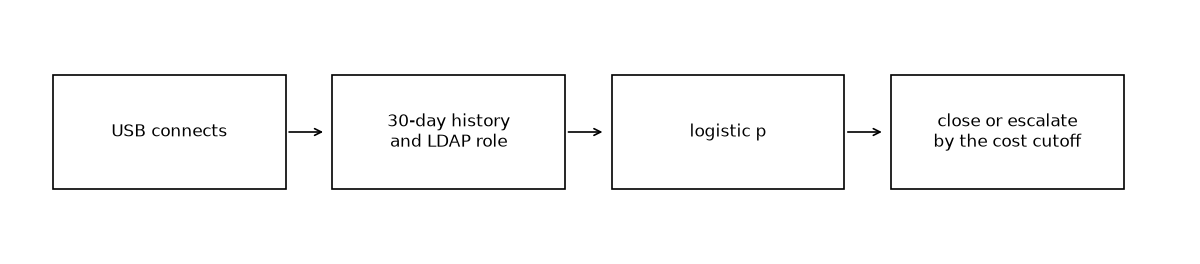

In [2]:
cert.layers_plot()
display(Image("fig/cert_layers.png"))


## Data

Release r6.1 of the CERT Insider Threat Test Dataset, Carnegie Mellon SEI, generated with ExactData. Local path `data/12841247/r6.1`. The files are synthetic. The ExactData terms in `license-exactdata.txt` do not allow republishing them. Download the archives from https://doi.org/10.1184/R1/12841247.v1. Provenance and hashes are in `data/README_cert.md`. The decision entry is `decisions_cert.md`.

The unit is one row of `device.csv` with activity Connect. A file-detection row from the endpoint export was one alert. CERT's file log is removable-media activity, and the answer key marks 7 of those rows. The same key marks 78 device rows, 39 of them connects, across scenarios 1, 2, and 3. A connect is the alert a USB control would open. Disconnects are the other 39 key rows and are not scored: counting both would score one insertion twice.

`y = 1` when the connect id is in the answer key. The other connects are `y = 0`. The key is not a feature. The user id is not a feature. `psychometric.csv` is not used: the release notes say those scores would be latent in a real deployment.

Scenario 4's observables file, `r6.1-4.csv`, is listed in `insiders.csv` and is not in `answers.tar.bz2`. That user has no row in `device.csv`. Scenario 5 is four web uploads and no device row. Neither enters this score. `http.csv` is 78 GB and `email.csv` is 7.7 GB; leaving them out means the score is silent on those two scenarios.


In [3]:
meta = prepared["meta"]
print(
    f"connects {meta['connects']:,}  disconnects {meta['disconnects']:,}  "
    f"file rows copied to removable media {meta['file_to_removable']:,}"
)
print(
    f"answer-key device ids {meta['answer_device_ids']}  "
    f"of which connects {meta['answer_ids_that_are_connects']}  "
    f"disconnects {meta['answer_ids_that_are_disconnects']}  "
    f"absent {meta['answer_ids_absent']}"
)
print("connects left unscored", prepared["excluded"])
print(prepared["incidents"].to_string(index=False))
print("December 2010 median connects in the prior 30 days, by LDAP role")
nonzero = prepared["role_table"][prepared["role_table"]["median_connects"] > 0]
print("roles with a non-zero median")
print(nonzero.to_string())
print("roles", len(prepared["role_table"]), "global median", prepared["global_median"])


connects 871,043  disconnects 865,754  file rows copied to removable media 623,511
answer-key device ids 78  of which connects 39  disconnects 39  absent 0
connects left unscored 0
 scenario    user  has_answer_file  device_ids_in_key  connects_labelled  connects_in_summary_window  connects_by_user               start                 end               role  after_hours_labelled  pc_mismatch_labelled
        1 CSF2712             True                  6                  3                           3                12 2011-01-06 04:51:28 2011-01-12 01:06:22 ElectricalEngineer                   3.0                   0.0
        2 JPH1910             True                 68                 34                          21               466 2011-01-12 11:12:06 2011-02-04 18:03:54      Mathematician                   2.0                   0.0
        3 HJB0462             True                  4                  2                           1                 2 2011-05-19 10:10:59 2011-05-19 17:

The summary window in `insiders.csv` is not the set of device events. Scenario 2's summary ends on 4 February 2011. That user has 21 connects inside the window, and none of those 21 ids is in the answer key. The 34 labelled connects run from 9 February through 7 March, after the published end. Scenario 3's summary ends at 17:06 on 19 May; one of the two labelled connects is at 21:29. The label follows the event id in the detail file.

In the 30 days before 1 January 2011, before any labelled connect, the median connect count is 0 for every role with more than two people. Attorney (2 people) and HealthSafetyEngineer (1 person) are the exceptions. The labelled roles are ElectricalEngineer, Mathematician, and ITAdmin, and each of those medians is 0.


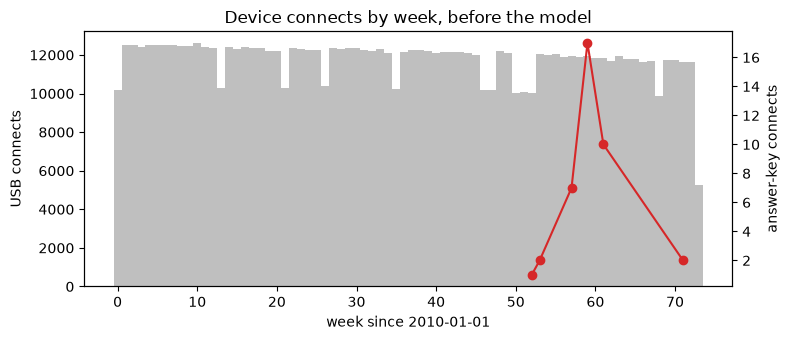

In [4]:
import matplotlib.pyplot as plt

frame = prepared["frame"]
week = frame["sec"] // (7 * 24 * 3600)
counts = frame.groupby(week).size()
malicious = frame[frame["y"] == 1].groupby(week).size()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(counts.index, counts.values, color="0.75", width=1.0)
ax2 = ax.twinx()
ax2.plot(malicious.index, malicious.values, color="C3", marker="o")
ax.set_xlabel("week since 2010-01-01")
ax.set_ylabel("USB connects")
ax2.set_ylabel("answer-key connects")
ax.set_title("Device connects by week, before the model")
fig.tight_layout()
fig.savefig("fig/cert_weekly.png", dpi=120)
plt.show()


## Split

The decision is about a later connect, so the holdout is a later time. The cutoff is 8 March 2011 00:00, the first midnight after the last scenario-2 connect. Training holds connects before that instant. The held-out set holds connects on or after it. Scenarios 1 and 2 stay in training. Scenario 3 stays in the held-out set. The cutoff does not slice a labelled scenario in half.

Usual PC and the role median are frozen on activity before 1 January 2011, which is before the first labelled connect. A connect's own prior 30 days run up to that connect, not up to the cutoff: those days are known when the connect happens.


In [5]:
train, test = prepared["train"], prepared["test"]
print("train", len(train), "labelled", int(train["y"].sum()))
print("test", len(test), "labelled", int(test["y"].sum()))
print("training rate", round(prepared["base_rate"], 6))
cols = ["after_hours", "prior_connects", "prior_after_logons", "prior_files_out", "pc_mismatch", "role_gap"]
print("training medians by label")
print(train.groupby("y")[cols].median().to_string())
gap = train["role_gap"].to_numpy(float)
raw = np.log1p(train["prior_connects"].to_numpy(float))
print("corr(role_gap, log prior connects)", round(float(np.corrcoef(gap, raw)[0, 1]), 4))


train 731999 labelled 37
test 139044 labelled 2
training rate 5.1e-05
training medians by label
   after_hours  prior_connects  prior_after_logons  prior_files_out  pc_mismatch  role_gap
y                                                                                         
0          0.0           174.0                14.0             36.0          0.0  5.164786
1          0.0            76.0                 8.0             36.0          0.0  4.343805
corr(role_gap, log prior connects) 0.999


## Baseline

Close every connect. On the held-out connects, the two scenario-3 connects are missed and nothing benign is escalated:

\[
\text{cost}_{\text{close all}} = 2\,C_{MISS}
\]

A rule that escalates \(k\) benign connects and misses \(m\) of the two costs

\[
\text{cost}(k, m) = k\,C_{FP} + m\,C_{MISS}
\]


In [6]:
print(f"close every connect: 0 C_FP + {int(test['y'].sum())} C_MISS on {len(test)} held-out connects")


close every connect: 0 C_FP + 2 C_MISS on 139044 held-out connects


## Model

Logistic regression, fitted by log loss on the training connects. \(y_i = 1\) when the connect id is in the answer key.

\[
p_i = \frac{1}{1 + \exp\!\big(-(\beta_0 + x_i^\top\beta)\big)}
\]

\[
\text{log loss} = -\frac{1}{n} \sum_{i=1}^{n} \Big[\, y_i \log p_i + (1 - y_i)\log(1 - p_i) \,\Big]
\]

\(\beta_0\) is the log-odds of a connect with every feature at zero: a daytime weekday connect, on the user's usual PC, with no connects, after-hours logons, or outbound file copies in the prior 30 days, and a role whose December median is also zero. `after_hours` is 1 when the connect is before 08:00, at or after 18:00, or on a weekend. The three `log_prior_*` terms are \(\log(1+\text{count})\) over the 30 days before the connect, not including the connect itself. `pc_mismatch` is 1 when the PC is not the user's most common logon PC before 1 January 2011. `role_gap` is

\[
\text{role gap}_i = \log(1+\text{prior connects}_i) - \log(1+\text{December median for the LDAP role}_i)
\]

The role name is not a coefficient. A coefficient on the job title would score the role. The proposal's input is the gap between recent activity and the role's norm.

The assumption trusted least is that the 37 training connects are 37 independent examples. Thirty-four of them are one user, from 9 February to 7 March, on that user's own PC. The Wald intervals below treat the rows as independent, so they are too narrow.

`history` drops `role_gap`. `history_role` keeps it, unpenalized. `history_role_l2` is the same design with an L2 penalty, \(C = 1\).


In [7]:
result = cert.fit_all(prepared)
rows = []
for name, fit in result["fits"].items():
    print(
        name,
        "max |coef|", round(fit["max_abs_coef"], 3),
        "train log loss", round(fit["train_log_loss"], 6),
        "test log loss", round(fit["test_log_loss"], 6),
        "test p max", round(float(fit["p_test"].max()), 6),
    )
    print("  intercept", round(float(fit["model"].intercept_[0]), 3))
    for feature, value in zip(fit["names"], fit["model"].coef_[0]):
        print(f"  {feature} {value:.4f}")
    for ratio in (1, 9):
        cutoff, false_pos, misses = cert.heldout_cost(fit["p_test"], fit["y_test"], ratio)
        rows.append({
            "rule": name,
            "C_MISS/C_FP": ratio,
            "cutoff": round(cutoff, 4),
            "false_positives": false_pos,
            "misses": misses,
            "cost": f"{false_pos} C_FP + {misses} C_MISS",
        })
constant = np.full(len(test), result["base_rate"])
print(
    "constant-rate held-out log loss",
    round(float(log_loss(test["y"], constant, labels=[0, 1])), 6),
)


history max |coef| 1.255 train log loss 0.00063 test log loss 0.000151 test p max 0.011896
  intercept -3.507
  after_hours -0.4352
  log_prior_connects -1.2550
  log_prior_after_logons -0.7637
  log_prior_files_out -0.0613
  pc_mismatch -0.0575
history_role max |coef| 0.671 train log loss 0.000614 test log loss 0.00015 test p max 0.009665
  intercept -3.751
  after_hours -0.4727
  log_prior_connects -0.6709
  log_prior_after_logons -0.6546
  log_prior_files_out -0.1117
  pc_mismatch -0.0649
  role_gap -0.4848
history_role_l2 max |coef| 0.666 train log loss 0.000612 test log loss 0.00015 test p max 0.009458
  intercept -3.776
  after_hours -0.4646
  log_prior_connects -0.6657
  log_prior_after_logons -0.6370
  log_prior_files_out -0.1150
  pc_mismatch -0.0639
  role_gap -0.4821
constant-rate held-out log loss 0.000193


## Uncertainty

The interval on a held-out probability is the delta method from the training Hessian. It is a 95% Wald interval under independent connects. Because one campaign supplies 34 of the 37 training labels, a believable interval is wider than the one printed.

The window check draws held-out labelled counts from the training rate, with seed `20261116`. It asks how often a window of this size would contain no labelled connect if that rate were real and the connects were independent. They are not: the two held-out labels are one afternoon.


In [8]:
chosen = result["fits"]["history_role"]
se, _cov = cert.wald_se(chosen["model"], chosen["x_train"])
print("Wald SE, unpenalized model with role_gap")
print("  intercept", round(float(se[0]), 4))
for feature, value in zip(chosen["names"], se[1:]):
    print(f"  {feature} {value:.4f}")

y_test = test["y"].to_numpy(int)
p_test = chosen["p_test"]
pos = y_test == 1
p_hat, low, high = cert.probability_interval(chosen["model"], chosen["x_test"][pos])
when = test.loc[pos, "when"].to_numpy()
print("held-out labelled connects")
for stamp, pi, lo, hi in zip(when, p_hat, low, high):
    print(f"  {stamp}  p {pi:.4f}  [{lo:.4f}, {hi:.4f}]")

order = np.argsort(-p_test)
y_order = y_test[order]
for rank in np.flatnonzero(y_order == 1):
    print(
        "labelled connect rank", int(rank) + 1,
        "p", round(float(p_test[order][rank]), 6),
        "connects with a higher p", int(rank),
    )
print("held-out mean p", round(float(p_test.mean()), 6), "observed rate", round(float(y_test.mean()), 6))

rng = np.random.default_rng(cert.SEED)
draws = rng.binomial(len(test), result["base_rate"], size=10000)
print(f"expected labelled connects in a window of {len(test)}: {draws.mean():.2f}")
print(f"share of draws with none: {(draws == 0).mean():.3f}")


Wald SE, unpenalized model with role_gap
  intercept 0.2306
  after_hours 0.5107
  log_prior_connects 0.5580
  log_prior_after_logons 0.1220
  log_prior_files_out 0.1375
  pc_mismatch 1.5847
  role_gap 0.5369
held-out labelled connects
  2011-05-19T17:03:04.000000  p 0.0018  [0.0000, 0.0851]
  2011-05-19T21:29:04.000000  p 0.0004  [0.0000, 0.0413]
labelled connect rank 179 p 0.001811 connects with a higher p 178
labelled connect rank 2593 p 0.000434 connects with a higher p 2592
held-out mean p 4.9e-05 observed rate 1.4e-05
expected labelled connects in a window of 139044: 7.03
share of draws with none: 0.001


## Residuals

Mean \(p\) on the held-out connects sits on the training rate. The held-out rate is lower, so ordinary weeks have a small negative residual: \(p\) is a little above \(y\). The week of 19 May is the spike the other way. The residual for connect \(i\) is \(r_i = y_i - p_i\), and the plot shows its mean within each week \(w\):

\[
\bar r_w = \frac{1}{|W_w|} \sum_{i \in W_w} (y_i - p_i)
\]

The two labelled connects are under-called, and they are still far below either cost cutoff. The histogram is zoomed to the range the model actually produces. The equal-cost cutoff, 0.5, is off the right edge.


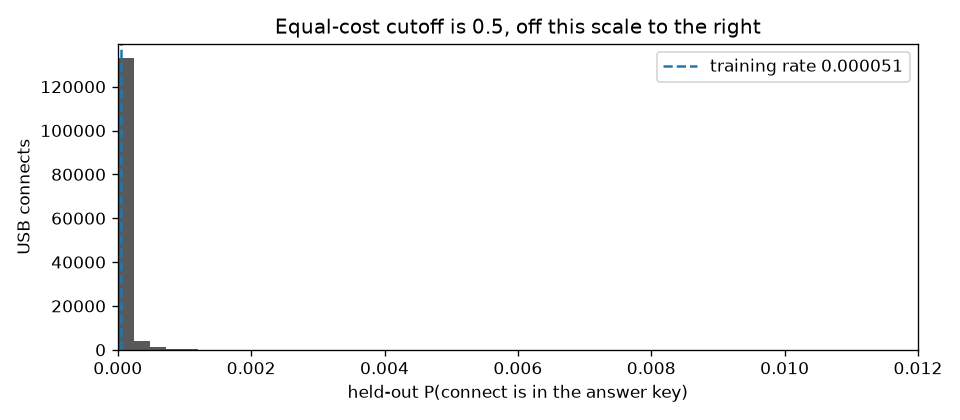

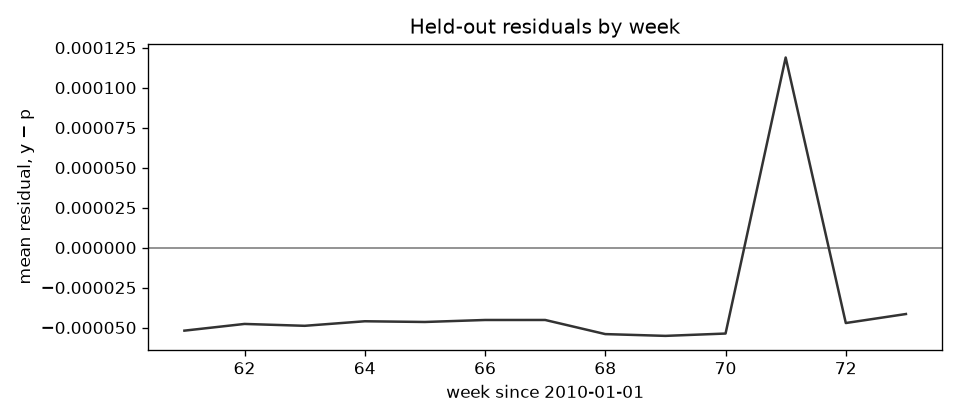

In [9]:
cert.save_plots(prepared["frame"], test, p_test, result["base_rate"])
display(Image("fig/cert_heldout_p.png"))
display(Image("fig/cert_residual_week.png"))


## Decision

Close every connect. At equal costs, and at a miss costing nine false escalations, every fitted rule escalates nobody and misses both labelled connects. The cost ties closing every connect:

\[
2\,C_{MISS}
\]

The louder May connect is rank 179. Escalating down through it also escalates 178 benign connects and still misses the other labelled connect. That costs \(178\,C_{FP} + 1\,C_{MISS}\), which is less than \(2\,C_{MISS}\) only when

\[
178\,C_{FP} + 1\,C_{MISS} < 2\,C_{MISS}
\qquad\Longleftrightarrow\qquad
C_{MISS} > 178\,C_{FP}
\]

Catching both means escalating the 2,591 benign connects ranked above the quieter one. That costs \(2{,}591\,C_{FP}\), which beats \(2\,C_{MISS}\) only when

\[
2{,}591\,C_{FP} < 2\,C_{MISS}
\qquad\Longleftrightarrow\qquad
C_{MISS} > 1{,}295.5\,C_{FP}
\]

`role_gap` correlates 0.999 with \(\log(1+\text{prior connects})\), because the December median is 0 for the roles in this fit. Dropping it does not change the held-out cost. The L2 fit does not either.

Log loss on the held-out set is about 0.000150 for the fitted models and 0.000193 for the constant training rate. The lower log loss does not change the action. The probabilities never cross 0.01, and the highest labelled probability is 0.0018.


In [10]:
rows.append({
    "rule": "close every connect",
    "C_MISS/C_FP": "any",
    "cutoff": None,
    "false_positives": 0,
    "misses": int(y_test.sum()),
    "cost": f"0 C_FP + {int(y_test.sum())} C_MISS",
})
print(pd.DataFrame(rows).to_string(index=False))


               rule C_MISS/C_FP  cutoff  false_positives  misses              cost
            history           1     0.5                0       2 0 C_FP + 2 C_MISS
            history           9     0.1                0       2 0 C_FP + 2 C_MISS
       history_role           1     0.5                0       2 0 C_FP + 2 C_MISS
       history_role           9     0.1                0       2 0 C_FP + 2 C_MISS
    history_role_l2           1     0.5                0       2 0 C_FP + 2 C_MISS
    history_role_l2           9     0.1                0       2 0 C_FP + 2 C_MISS
close every connect         any     NaN                0       2 0 C_FP + 2 C_MISS


## Limits

The label is the red team's event list, not an analyst's verdict on an antivirus alert. Scenarios 4 and 5 never become a connect, so this score cannot catch them. The 37 training labels are two campaigns, and the two held-out labels are a third campaign on one afternoon. One of those two is on another PC, and none of the training labels are: `pc_mismatch` has nothing labelled to learn from.

The negative coefficients are a fact about this unit. A connect from a user with a long USB history looks less like the training labels than a connect from a quieter user. That is not "the user just started using a drive." People who connect every day produce most of the rows, and their connects are benign. What would make the sign wrong for the decision is a held-out campaign whose first connects, the ones with an empty prior 30 days, carry \(p\) over the cost cutoff. Here the largest held-out \(p\) is under 0.01.

The model should not be used to escalate, and it should not be used to judge an employee. A person makes the call. With the web log, scenario 5 could enter the score. With `r6.1-4.csv`, scenario 4 could get a label. Until a labelled connect clears the cost cutoff without a long line of benign connects above it, the lower held-out cost is to close every connect.
